# 03_analyse_visualisation : niveaux des nappes, station par station

**Objectif** : à partir des données brutes téléchargées par `02_chroniques`, contrôler leur qualité, les préparer, puis les analyser.

- Source : API Hub'Eau « Piézométrie » (https://hubeau.eaufrance.fr/page/api-piezometrie)
- Le projet se fait en trois notebooks :
    1. `01_stations` : liste des stations de la zone (endpoint `/stations`) ; **c'est là que se définit la zone géographique**
    2. `02_chroniques` : téléchargement des mesures de chaque station (endpoint `/chroniques`), enregistrées à l'état brut
    3. **`03_analyse_visualisation` (ce notebook)** : contrôle qualité, préparation et analyse des mesures

**Entrées** (aucun appel à l'API dans ce notebook)
- `data/raw/chroniques_<PERIODE>_extrait_le_AAAA-MM-JJ.json` : produit par `02_chroniques` (le plus récent est utilisé)
- `data/processed/stations_mesurees.csv` : produit par `01_stations` (pour comparer avec le nombre de mesures annoncé)

**Étapes**
1. Imports
2. Configuration : période à analyser, chemins
3. Chargement des données brutes et des stations
4. Mise en DataFrame et contrôle qualité
5. Sauvegarde des données préparées (`data/processed/`)
6. Analyse et visualisation *(à venir)*

**Sorties**
- `data/processed/chroniques_<PERIODE>.csv` : mesures préparées (colonnes utiles, triées), format long

### Prérequis avant d'utiliser le notebook

**Première installation (une seule fois)**
- Cloner le dépôt, puis dans le terminal, à la racine du projet :
  `python3 -m venv .venv` → `source .venv/bin/activate` → `pip install -r requirements.txt`
- Créer le fichier de variables : `cp .env.example .env`

**À chaque session de travail**
- Ouvrir le **dossier racine** `Hub-eau` dans VS Code (pas seulement le notebook)
- Récupérer les dernières modifications : `git pull`
- Vérifier que le **kernel** sélectionné (en haut à droite) est `.venv`
- Exécuter la cellule de vérification ci-dessous

**Pour installer une nouvelle bibliothèque**
- Activer le venv dans le terminal : `source .venv/bin/activate` (l'invite doit commencer par `(.venv)`)
- `pip install <bibliothèque>`, puis `pip freeze > requirements.txt`, puis commit

**Avant chaque commit**
- *Restart Kernel* + *Run All* : le notebook doit tourner en entier sans erreur
- `git status` : `.env`, `.venv/` et les fichiers de `data/` ne doivent jamais apparaître

### Réutiliser le notebook

Tout se règle dans la cellule **« 2. Configuration »** :

| Je veux… | Variable à modifier |
|---|---|
| analyser l'historique complet (par défaut) | `PERIODE = "historique_complet"` |
| analyser une extraction « depuis une date » faite avec le 02 | `PERIODE = "depuis_AAAA-MM-JJ"` |

- **Autre territoire** : exécuter `01_stations` puis `02_chroniques` sur la nouvelle zone, puis ce notebook sans rien changer.
- Le **constat** (après l'étape 4) décrit une extraction précise : à mettre à jour à chaque nouvelle extraction.

In [1]:
# Vérification de l'environnement : le kernel doit être celui du .venv du projet
import sys

print("Python utilisé :", sys.executable)
assert ".venv" in sys.executable, "⚠️ Mauvais kernel : sélectionner le .venv en haut à droite"

Python utilisé : /home/data-08/Documents/00-PROJETS/Hub-eau/.venv/bin/python


In [2]:
# 1. Imports des bibliothèques

# Bibliothèque standard (livrée avec Python)
import json                         # lecture des données brutes
from pathlib import Path            # chemins de fichiers (data/raw/...)

# Bibliothèques externes (installées dans le .venv, listées dans requirements.txt)
import pandas as pd                 # mise en DataFrame, contrôle et préparation des données
import matplotlib.pyplot as plt     # graphiques (timeline des niveaux)
import geopandas as gpd             # données géographiques et cartes (stations)


In [3]:
# 2. Configuration

# --- A. Période à analyser : doit correspondre à une extraction faite par 02_chroniques ---
# "historique_complet" (par défaut) ou "depuis_AAAA-MM-JJ"
PERIODE = "historique_complet"

# --- B. Chemins du projet ---
PROJECT_ROOT = Path.cwd().parent                # le notebook est dans notebooks/ => on remonte d'un niveau
assert (PROJECT_ROOT / "requirements.txt").exists(), f"Racine du projet incorrecte : {PROJECT_ROOT}"

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

FICHIER_STATIONS = DATA_PROCESSED / "stations_mesurees.csv"        # produit par 01_stations
FICHIER_STATIONS_GEO = DATA_PROCESSED / "stations_total.geojson"   # produit par 01_stations, pour la carte
SEUIL_LIMITE_API = 0.9                          # alerte si une station dépasse 90 % de la limite de l'API

# --- Récapitulatif ---
print("Période          :", PERIODE)
print("Racine projet    :", PROJECT_ROOT)
print("Fichier stations :", FICHIER_STATIONS)

Période          : historique_complet
Racine projet    : /home/data-08/Documents/00-PROJETS/Hub-eau
Fichier stations : /home/data-08/Documents/00-PROJETS/Hub-eau/data/processed/stations_mesurees.csv


#### 3. Chargement des données

- **Chroniques** : on prend le fichier le plus récent pour la période choisie. Il contient les mesures (`data`) et le **contexte de l'extraction** (date, paramètres, stations interrogées, erreurs) : on en tire les informations dont le contrôle qualité a besoin, sans dépendre des variables du 02.
- **Stations** : le CSV du 01 donne le nombre de mesures annoncé par `/stations`, pour vérifier que tout a été récupéré.

In [4]:
# 3a. Chargement des chroniques brutes (sortie du notebook 02_chroniques)

fichiers = sorted(DATA_RAW.glob(f"chroniques_{PERIODE}_extrait_le_*.json"))
if not fichiers:
    raise FileNotFoundError(f"Aucun fichier chroniques_{PERIODE}_… dans {DATA_RAW} : exécuter d'abord 02_chroniques")
fichier_brut = fichiers[-1]         # le plus récent (dates AAAA-MM-JJ => l'ordre alphabétique = l'ordre chronologique)

with open(fichier_brut, encoding="utf-8") as f:
    contenu_brut = json.load(f)

# Contexte de l'extraction, réutilisé dans le contrôle qualité
date_debut_demandee = contenu_brut["params"]["date_debut_mesure"]    # None = historique complet
limite_api = contenu_brut["params"]["size"]                          # nombre max de mesures par station
codes_stations = contenu_brut["stations_interrogees"]

print("Fichier             :", fichier_brut.name)
print("Date d'extraction   :", contenu_brut["date_extraction"])
print("Période demandée    :", date_debut_demandee or "historique complet")
print("Stations interrogées:", len(codes_stations))
print("Stations en échec   :", contenu_brut["erreurs"] or "aucune ✅")
print("Mesures             :", contenu_brut["nb_resultats"])

Fichier             : chroniques_historique_complet_extrait_le_2026-11-16.json
Date d'extraction   : 2026-11-16T11:08:18
Période demandée    : historique complet
Stations interrogées: 60
Stations en échec   : aucune ✅
Mesures             : 344995


In [5]:
# 3b. Chargement des stations avec mesures (sortie du notebook 01_stations)

if not FICHIER_STATIONS.exists():
    raise FileNotFoundError(f"{FICHIER_STATIONS} introuvable : exécuter d'abord le notebook 01_stations")

df_stations_mesurees = pd.read_csv(FICHIER_STATIONS,
                                   parse_dates=["date_debut_mesure", "date_fin_mesure"])

# Stations arrêtées avant la période demandée => 0 mesure attendue (ce n'est pas une erreur)
# Historique complet : aucune station concernée
if date_debut_demandee:
    arretees = df_stations_mesurees[df_stations_mesurees["date_fin_mesure"] < date_debut_demandee]
else:
    arretees = df_stations_mesurees.iloc[0:0]      # tableau vide, mêmes colonnes

print(f"{len(df_stations_mesurees)} stations dans {FICHIER_STATIONS.name}")
print(f"{len(arretees)} station(s) arrêtée(s) avant la période")

60 stations dans stations_mesurees.csv
0 station(s) arrêtée(s) avant la période


#### 4. Mise en DataFrame et contrôle qualité

- 4a. Création du DataFrame et conversion des dates, puis valeurs possibles de chaque colonne
- 4b. Valeurs manquantes et doublons
- 4c. Couverture : nombre de mesures et période par station, stations sans mesure
- 4d. Fiabilité des mesures : qualification, statut, mode d'obtention

In [6]:
# 4a. Création du DataFrame et conversion des types

df_chroniques = pd.DataFrame(contenu_brut["data"])
df_chroniques["date_mesure"] = pd.to_datetime(df_chroniques["date_mesure"])

print("Dimensions (lignes, colonnes) :", df_chroniques.shape)
df_chroniques.info()

Dimensions (lignes, colonnes) : (344995, 16)
<class 'pandas.DataFrame'>
RangeIndex: 344995 entries, 0 to 344994
Data columns (total 16 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   code_bss            344995 non-null  str           
 1   bss_id              344995 non-null  str           
 2   urn_bss             344995 non-null  str           
 3   date_mesure         344995 non-null  datetime64[us]
 4   timestamp_mesure    344995 non-null  int64         
 5   niveau_nappe_eau    344995 non-null  float64       
 6   mode_obtention      344995 non-null  str           
 7   statut              344995 non-null  str           
 8   qualification       344995 non-null  str           
 9   code_continuite     344995 non-null  str           
 10  nom_continuite      344995 non-null  str           
 11  code_producteur     344863 non-null  str           
 12  nom_producteur      344863 non-null  str           


In [7]:
# 4a bis. Contenu des colonnes : valeurs possibles pour les colonnes à choix prédéfinis
# Une colonne est considérée « à choix prédéfinis » si elle a peu de valeurs différentes (≤ MAX_MODALITES)
# Les autres colonnes (identifiants, dates, mesures) sont résumées : nombre de valeurs différentes, min et max
# Le résultat est affiché ET enregistré dans un fichier texte (data/processed/)

MAX_MODALITES = 20
NOM_FICHIER = "chroniques"          # préfixe du fichier texte produit

lignes = [f"Contenu des colonnes du fichier {fichier_brut.name}",
          f"Date d'extraction : {contenu_brut['date_extraction']}",
          f"{len(df_chroniques)} mesures, {df_chroniques.shape[1]} colonnes",
          ""]

for colonne in df_chroniques.columns:
    serie = df_chroniques[colonne]
    nb_valeurs = serie.nunique(dropna=True)
    nb_manquants = serie.isna().sum()
    lignes.append(f"■ {colonne}  ({serie.dtype}, {nb_valeurs} valeur(s) différente(s), {nb_manquants} manquante(s))")

    if nb_valeurs <= MAX_MODALITES:
        # Choix prédéfinis : chaque valeur avec son nombre de mesures (les manquantes incluses)
        for valeur, nb in serie.value_counts(dropna=False).items():
            lignes.append(f"      - {valeur!s:<45} {nb:>8} mesures")
    elif pd.api.types.is_numeric_dtype(serie) or pd.api.types.is_datetime64_any_dtype(serie):
        lignes.append(f"      de {serie.min()} à {serie.max()}")
    else:
        lignes.append(f"      exemple : {serie.dropna().iloc[0]}")
    lignes.append("")

texte = "\n".join(lignes)
print(texte)

# Enregistrement dans un fichier texte
fichier_contenu = DATA_PROCESSED / f"{NOM_FICHIER}_contenu_colonnes.txt"
fichier_contenu.write_text(texte, encoding="utf-8")
print(f"✅ Contenu des colonnes enregistré dans : {fichier_contenu}")

Contenu des colonnes du fichier chroniques_historique_complet_extrait_le_2026-11-16.json
Date d'extraction : 2026-11-16T11:08:18
344995 mesures, 16 colonnes

■ code_bss  (str, 57 valeur(s) différente(s), 0 manquante(s))
      exemple : 08422X0190/F1

■ bss_id  (str, 57 valeur(s) différente(s), 0 manquante(s))
      exemple : BSS001ZWRZ

■ urn_bss  (str, 57 valeur(s) différente(s), 0 manquante(s))
      exemple : http://services.ades.eaufrance.fr/pointeau/08422X0190/F1

■ date_mesure  (datetime64[us], 15478 valeur(s) différente(s), 0 manquante(s))
      de 1974-10-15 00:00:00 à 2026-11-13 00:00:00

■ timestamp_mesure  (int64, 107071 valeur(s) différente(s), 0 manquante(s))
      de 151027200000 à 1794546000000

■ niveau_nappe_eau  (float64, 16235 valeur(s) différente(s), 0 manquante(s))
      de 74.9 à 986.43

■ mode_obtention  (str, 3 valeur(s) différente(s), 0 manquante(s))
      - Valeur mesurée                                  328826 mesures
      - Valeur reconstituée              

In [8]:
# 4b. Contrôle qualité : valeurs manquantes, doublons

# Valeurs manquantes par colonne (uniquement celles qui en ont)
manquants = df_chroniques.isna().sum()
print("Valeurs manquantes :\n", manquants[manquants > 0].sort_values(ascending=False))

# Doublons : une seule mesure attendue par station et par jour
doublons = df_chroniques.duplicated(subset=["code_bss", "date_mesure"]).sum()
print("\nDoublons (code_bss + date_mesure) :", doublons)

Valeurs manquantes :
 nom_nature_mesure     11773
code_nature_mesure    11773
nom_producteur          132
code_producteur         132
dtype: int64

Doublons (code_bss + date_mesure) : 0


In [9]:
# 4c. Couverture : nombre de mesures et période couverte par station

couverture = (df_chroniques
              .groupby("code_bss")
              .agg(nb_mesures=("date_mesure", "size"),
                   premiere_mesure=("date_mesure", "min"),
                   derniere_mesure=("date_mesure", "max"))
              .sort_values("nb_mesures"))

print(f"{len(couverture)} stations avec des mesures, sur {len(codes_stations)} interrogées")
print("\nNombre de mesures par station :")
print(couverture["nb_mesures"].describe().round(0))

# Limite de l'API : une station proche de la limite (20 000) risquerait d'être tronquée
print(f"\nStations proches de la limite de {limite_api} mesures :",
      couverture.index[couverture["nb_mesures"] > SEUIL_LIMITE_API * limite_api].tolist() or "aucune ✅")

# Historique complet : on compare au nombre de mesures annoncé par /stations (notebook 01)
# Quelques mesures d'écart sont normales : de nouvelles mesures arrivent chaque jour
if not date_debut_demandee:
    ecart = couverture["nb_mesures"] - df_stations_mesurees.set_index("code_bss")["nb_mesures_piezo"]
    print(f"\nÉcart avec /stations : de {ecart.min():.0f} à {ecart.max():.0f} mesure(s) par station")

# Stations sans aucune mesure : normal si elles sont arrêtées avant la période (étape 3b),
# sinon /stations annonce des mesures que /chroniques ne diffuse pas => à signaler dans le constat
sans_mesure = set(codes_stations) - set(couverture.index)
inexpliquees = sans_mesure - set(arretees["code_bss"])
print(f"\n{len(sans_mesure)} station(s) sans mesure, dont {len(inexpliquees)} non expliquée(s) par la période")
display(df_stations_mesurees.loc[df_stations_mesurees["code_bss"].isin(inexpliquees),
                                 ["code_bss", "nom_commune", "date_debut_mesure",
                                  "date_fin_mesure", "nb_mesures_piezo"]])

couverture.head(10)   # les stations les moins fournies

57 stations avec des mesures, sur 60 interrogées

Nombre de mesures par station :
count       57.0
mean      6053.0
std       2912.0
min         71.0
25%       4912.0
50%       6162.0
75%       8455.0
max      11269.0
Name: nb_mesures, dtype: float64

Stations proches de la limite de 20000 mesures : aucune ✅

Écart avec /stations : de 0 à 0 mesure(s) par station

3 station(s) sans mesure, dont 3 non expliquée(s) par la période


,code_bss,nom_commune,date_debut_mesure,date_fin_mesure,nb_mesures_piezo
23,08188X0054/F,La Baume-Cornillane,2009-06-12,2013-03-08,1366
25,07952X0027/F,Châtillon-Saint-Jean,2009-08-11,2013-01-11,1245
46,08666X0161/PUITS,Montboucher-sur-Jabron,2009-06-26,2013-01-08,1113


,nb_mesures,premiere_mesure,derniere_mesure
code_bss,,,
BSS004GTLS/X,71,2025-08-05,2025-10-14
07476X0034/PZF3,152,2025-05-16,2025-10-14
BSS004NBZY/X,474,2024-04-19,2025-08-05
BSS004GYJR/X,915,2023-03-15,2026-04-24
07944X0048/S,1259,1988-05-31,1998-04-28
08413X0081/LAUZAS,1381,1997-02-12,2002-02-26
08184X0069/S,1453,1982-02-04,1998-08-22
07965X0092/F,1713,2021-06-25,2026-10-14
08651X0038/0038,1762,2021-12-14,2026-11-12


In [10]:
# 4d. Fiabilité des mesures : répartition des valeurs (en % des mesures)

for colonne in ["qualification", "statut", "mode_obtention"]:
    print(f"\n--- {colonne} ---")
    print((df_chroniques[colonne].value_counts(dropna=False, normalize=True) * 100).round(1))


--- qualification ---
qualification
Correcte        97.3
Incertaine       1.9
Non qualifié     0.8
Incorrecte       0.0
Name: proportion, dtype: float64

--- statut ---
statut
Donnée contrôlée niveau 2    84.8
Donnée contrôlée niveau 1    11.2
Donnée interprétée            3.2
Donnée brute                  0.8
Name: proportion, dtype: float64

--- mode_obtention ---
mode_obtention
Valeur mesurée              95.3
Valeur reconstituée          3.6
Mode d'obtention inconnu     1.1
Name: proportion, dtype: float64


**Constat** (extraction du 12/11/2026, historique complet) : *à mettre à jour à chaque nouvelle extraction*

- **344 920 mesures**, du **15/10/1974** au **11/11/2026**, pour **57 stations** sur 60 ; **aucun doublon** station + date (au plus une mesure par jour).
- **3 stations sans mesure** (`07952X0027/F`, `08188X0054/F`, `08666X0161/PUITS`) : `/stations` leur attribue 1 100 à 1 400 mesures entre 2009 et 2013, mais `/chroniques` n'en renvoie aucune, même interrogée par `bss_id`. Ces données ne sont pas diffusées par l'API : rien à corriger dans le code.
- Pour les 57 autres stations, l'écart avec `/stations` est de 0 à 7 mesures (mesures arrivées depuis l'exécution du 01). Station la plus fournie : 11 267 mesures, sous la limite de 20 000 (limite de l'API).
- **Couverture très inégale** : de 71 mesures (station ouverte en 2025) à plus de 11 000 ; 19 stations ont commencé avant 2000, plusieurs se sont arrêtées vers 1998-2002, 47 sont encore actives. À prendre en compte avant de comparer des stations entre elles.
- **Valeurs manquantes** : uniquement la nature de la mesure (~11 800) et le producteur (132), sans impact sur les niveaux d'eau.
- **Fiabilité** : 97,3 % des mesures « Correcte », 95,9 % contrôlées (niveau 1 ou 2), 3,6 % reconstituées. Les mesures « Incertaine », « Incorrecte » ou « Non qualifié » pourront être exclues lors de l'analyse.
- Les codes `BSS…/X` sont le nouveau format d'identifiant BSS. Ils sont identiques dans les stations et les chroniques, donc la jointure fonctionne.

#### 5. Sauvegarde des données préparées

On ne garde que les colonnes utiles à l'analyse ; les autres restent disponibles dans le fichier brut.
Format **long** : 1 ligne = 1 station × 1 date, trié par station puis par date.

In [11]:
# 5. Sauvegarde des données préparées (data/processed/)

COLONNES_UTILES = [
    "code_bss",            # identifiant de la station (clé de jointure avec les stations)
    "date_mesure",
    "niveau_nappe_eau",    # altitude de la surface de l'eau (m NGF)
    "profondeur_nappe",    # profondeur de l'eau sous le sol (m)
    "qualification",       # fiabilité de la mesure
    "statut",              # niveau de contrôle de la donnée
    "mode_obtention",
]

df_chroniques_propre = (df_chroniques[COLONNES_UTILES]
                        .sort_values(["code_bss", "date_mesure"])
                        .reset_index(drop=True))

fichier_traite = DATA_PROCESSED / f"chroniques_{PERIODE}.csv"
df_chroniques_propre.to_csv(fichier_traite, index=False)

print(f"✅ {len(df_chroniques_propre)} mesures sauvegardées dans : {fichier_traite}")
df_chroniques_propre.head()

✅ 344995 mesures sauvegardées dans : /home/data-08/Documents/00-PROJETS/Hub-eau/data/processed/chroniques_historique_complet.csv


,code_bss,date_mesure,niveau_nappe_eau,profondeur_nappe,qualification,statut,mode_obtention
0,07475X0008/F3,1999-03-16,289.46,20.72,Correcte,Donnée contrôlée niveau 2,Valeur mesurée
1,07475X0008/F3,1999-03-19,289.44,20.74,Correcte,Donnée contrôlée niveau 2,Valeur mesurée
2,07475X0008/F3,1999-03-21,289.47,20.71,Correcte,Donnée contrôlée niveau 2,Valeur mesurée
3,07475X0008/F3,1999-03-23,289.47,20.71,Correcte,Donnée contrôlée niveau 2,Valeur mesurée
4,07475X0008/F3,1999-03-26,289.51,20.67,Correcte,Donnée contrôlée niveau 2,Valeur mesurée


In [12]:
# Vérification : relecture du fichier sauvegardé (un CSV ne conserve pas les types => parse_dates)
relu = pd.read_csv(fichier_traite, parse_dates=["date_mesure"])

print("Nombre de mesures :", len(relu))
assert len(relu) == len(df_chroniques_propre), "⚠️ Le fichier relu ne correspond pas aux données préparées"

Nombre de mesures : 344995


#### 6. Analyse et visualisation de la carte des stations

##### 6a. Carte des stations

Toutes les stations de la zone (`stations_total.geojson`, produit par `01_stations`) : en bleu celles qui ont des mesures, en gris les autres.
Carte interactive : zoom à la molette, informations de la station au survol.


In [13]:
# 6a. Carte des stations

# Lecture du GeoJSON : un GeoDataFrame = un DataFrame + une colonne "geometry" (ici des points)
if not FICHIER_STATIONS_GEO.exists():
    raise FileNotFoundError(f"{FICHIER_STATIONS_GEO} introuvable : exécuter d'abord le notebook 01_stations")

gdf_stations = gpd.read_file(FICHIER_STATIONS_GEO)
print(f"{len(gdf_stations)} stations, système de coordonnées : {gdf_stations.crs}")

# Libellé lisible pour la légende (au lieu de True / False)
gdf_stations["statut_carte"] = gdf_stations["avec_mesures"].map({True: "Avec mesures",
                                                                 False: "Sans mesure"})

# Carte interactive
carte = gdf_stations.explore(
    column="statut_carte",                  # couleur selon cette colonne
    categorical=True,                       # valeurs = catégories (pas une échelle continue)
    cmap=["#1f77b4", "#b0b0b0"],            # bleu = avec mesures, gris = sans mesure (ordre alphabétique des catégories)
    tiles="Esri.WorldTopoMap",              # fond de carte (OpenStreetMap bloque les cartes ouvertes hors d'un site web)
    tooltip=["code_bss", "nom_commune", "nb_mesures_piezo",
             "date_debut_mesure", "date_fin_mesure"],      # infos affichées au survol
    marker_kwds={"radius": 6},              # taille des points
    legend_kwds={"caption": "Stations piézométriques"},
)

# Enregistrement de la carte (fichier HTML autonome, s'ouvre dans un navigateur)
fichier_carte = DATA_PROCESSED / "carte_stations.html"
carte.save(fichier_carte)
print(f"✅ Carte enregistrée dans : {fichier_carte}")

carte      # affichage dans le notebook (si VS Code l'autorise)

176 stations, système de coordonnées : EPSG:4326
✅ Carte enregistrée dans : /home/data-08/Documents/00-PROJETS/Hub-eau/data/processed/carte_stations.html


#### 7. Analyse et visualisation de la timeline du niveau des nappes phréatiques

##### 7a. Timeline du niveau des nappes phréatiques

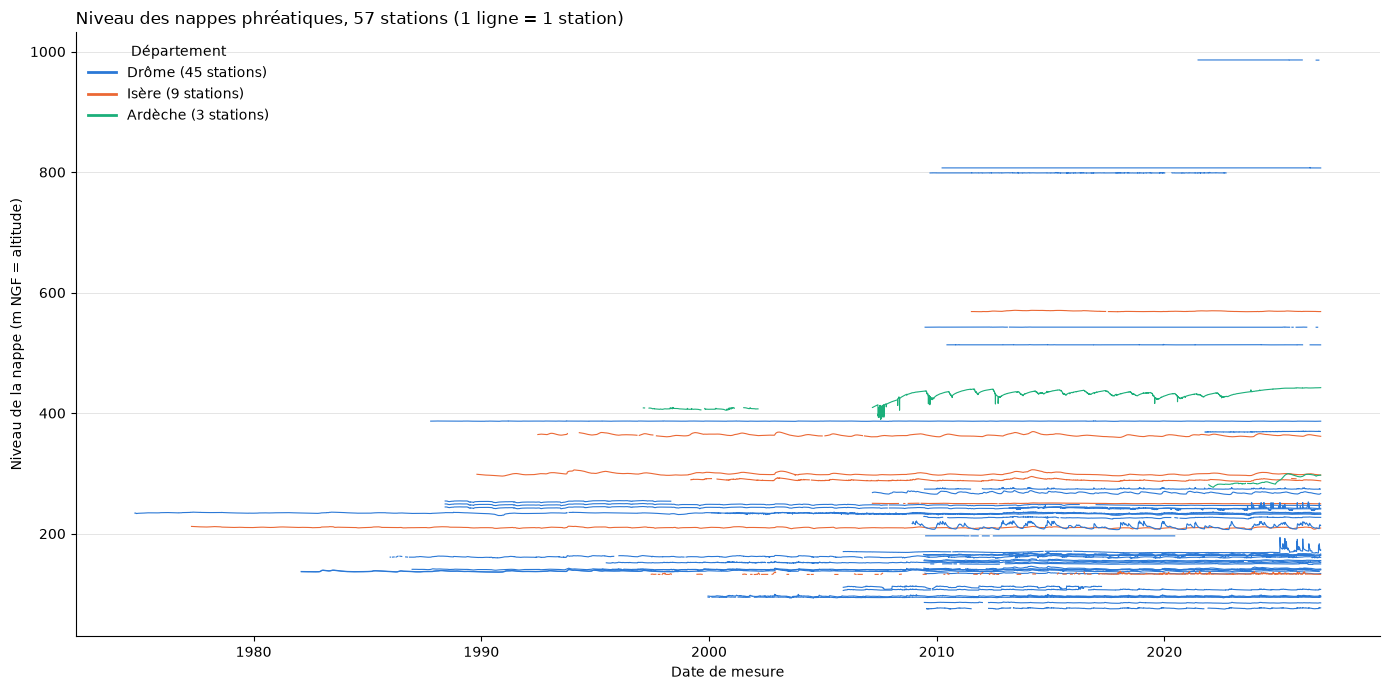

In [14]:
# 7a. Timeline du niveau des nappes : 1 ligne = 1 station
# Couleur = département (une couleur par station serait illisible avec 57 stations)

ECART_MAX_JOURS = 30        # au-delà, on coupe la ligne : pas de trait droit à travers une période sans mesure
COULEURS_DEPARTEMENTS = {"Drôme": "#2a78d6", "Isère": "#eb6834", "Ardèche": "#1baf7a"}

# Ajout du département de chaque station (jointure avec le CSV du 01 sur code_bss)
df_timeline = df_chroniques_propre.merge(df_stations_mesurees[["code_bss", "nom_departement"]],
                                         on="code_bss", how="left")

fig, ax = plt.subplots(figsize=(14, 7))

for (code, departement), mesures in df_timeline.groupby(["code_bss", "nom_departement"]):
    mesures = mesures.set_index("date_mesure")["niveau_nappe_eau"]
    # Coupure de la ligne : on insère une valeur vide après chaque trou de plus de ECART_MAX_JOURS
    trous = mesures.index.to_series().diff() > pd.Timedelta(days=ECART_MAX_JOURS)
    for date_reprise in mesures.index[trous]:
        mesures.loc[date_reprise - pd.Timedelta(days=1)] = float("nan")
    mesures = mesures.sort_index()

    ax.plot(mesures.index, mesures.values, linewidth=0.8,
            color=COULEURS_DEPARTEMENTS.get(departement, "gray"))

# Légende : une entrée par département (avec le nombre de stations)
nb_par_dep = df_timeline.groupby("nom_departement")["code_bss"].nunique()
ax.legend(handles=[plt.Line2D([], [], color=c, linewidth=2, label=f"{dep} ({nb_par_dep.get(dep, 0)} stations)")
                   for dep, c in COULEURS_DEPARTEMENTS.items()],
          title="Département", loc="upper left", frameon=False)

ax.set_title(f"Niveau des nappes phréatiques, {df_timeline['code_bss'].nunique()} stations (1 ligne = 1 station)",
             loc="left")
ax.set_xlabel("Date de mesure")
ax.set_ylabel("Niveau de la nappe (m NGF = altitude)")
ax.grid(axis="y", color="#e0e0e0", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()